# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [2]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [3]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,12.879967,12.534007,S-G1
1,1,osimertinib,B,tago-01560,-1.712741,11.650750,P
2,2,osimertinib,A,tago-02253,12.870441,12.998882,S-G1
3,3,osimertinib,A,tago-01478,15.319292,1.937557,S-syn
4,4,osimertinib,A,tago-02626,13.258777,12.765258,S-G1


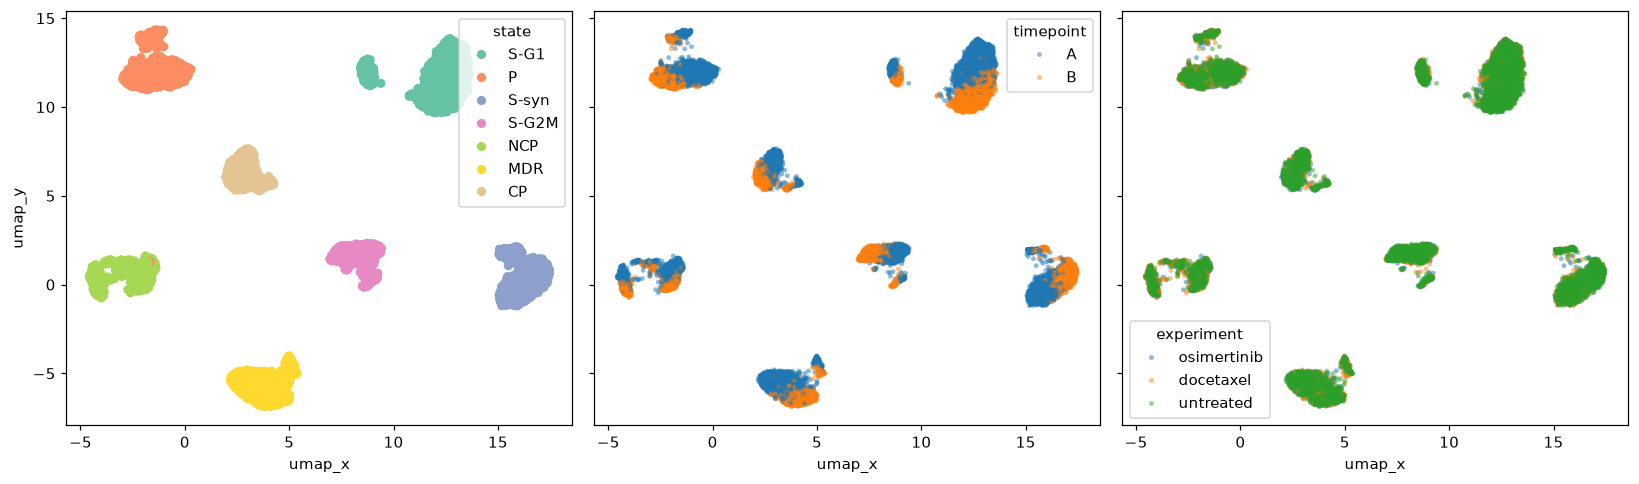

In [4]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [5]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [6]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [7]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [8]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [9]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [10]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

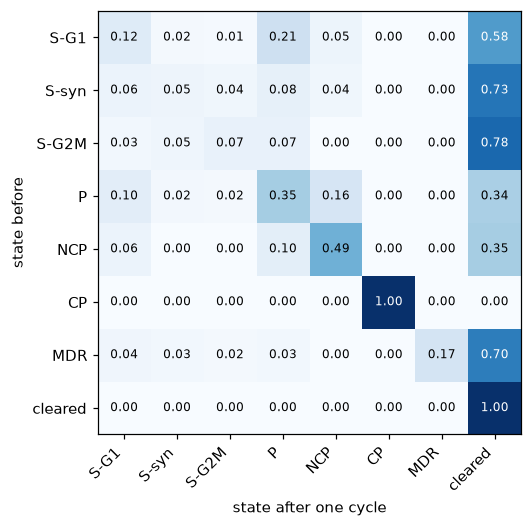

In [11]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

*Answer here.*
- CP or Cycling Persister is the only one that completely absorbs osimertinib (has a 1 on the diagonal and 0 in the cleared column), the next closest is NCP which is persistent, but does not absord since it gets somewhat cleared each round.
- This means that the drug osimertinib cannot kill the CP cells, so we can actually clear a lot of the other cells of the tumor, but we cannot clear the tumor because it will now just be made up of those CP cells.

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

In [12]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [13]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [14]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

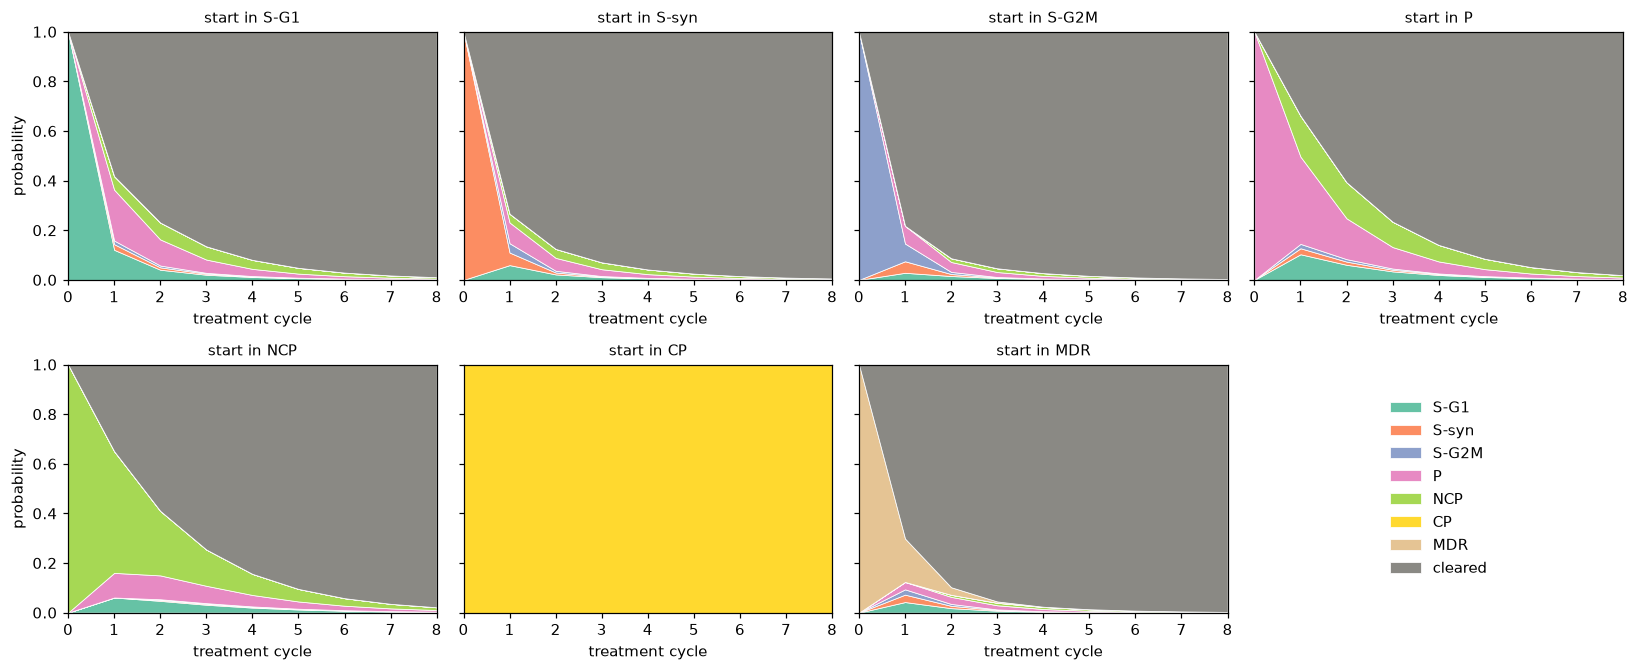

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [15]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>



- Osimertinib eventually clears every state except CP. S-syn, S-G2M and MDR clear fastest, while P and NCP clear a little slower.
- NCP lasts longest of the clearable states with .022 after the 8th cycle.
- CP is never cleared so it sticks around the most.
-  CP is 100% alive, the second closest is NCP at 25% after 3 cycles

In [16]:
alive_3 = {s: 1 - evolve(basis(s, P_hat), P_hat.to_numpy(), 3)[-1, -1] for s in STATES}
alive_8 = {s: 1 - evolve(basis(s, P_hat), P_hat.to_numpy(), 8)[-1, -1] for s in STATES}
pd.DataFrame({"alive after 3 cycles": alive_3, "alive after 8 cycles": alive_8}).round(4)

,alive after 3 cycles,alive after 8 cycles
S-G1,0.1352,0.0108
S-syn,0.0707,0.0056
S-G2M,0.0467,0.0036
P,0.2344,0.0190
NCP,0.2543,0.0216
CP,1.0000,1.0000
MDR,0.0451,0.0029


### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

{'S-G1': np.float64(0.247), 'S-syn': np.float64(0.148), 'S-G2M': np.float64(0.099), 'P': np.float64(0.153), 'NCP': np.float64(0.102), 'CP': np.float64(0.097), 'MDR': np.float64(0.153), 'cleared': np.float64(0.0)}


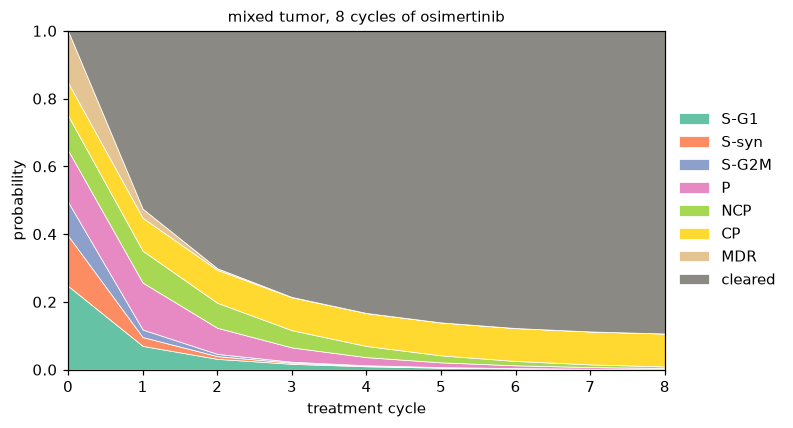

after 8 cycles:


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.001,0.0,0.0,0.003,0.005,0.097,0.0,0.893


share of surviving cells by state: {'S-G1': np.float64(0.012), 'S-syn': np.float64(0.002), 'S-G2M': np.float64(0.001), 'P': np.float64(0.028), 'NCP': np.float64(0.045), 'CP': np.float64(0.912), 'MDR': np.float64(0.0)}
after 50 cycles: {'S-G1': np.float64(0.0), 'S-syn': np.float64(0.0), 'S-G2M': np.float64(0.0), 'P': np.float64(0.0), 'NCP': np.float64(0.0), 'CP': np.float64(0.097), 'MDR': np.float64(0.0), 'cleared': np.float64(0.903)}


In [17]:
# Your code here

pi_mix = (cells[cells.timepoint == "A"]["state"]
          .value_counts(normalize = True)
          .reindex(OUTCOMES, fill_value = 0)
          .to_numpy())
print(dict(zip(OUTCOMES, pi_mix.round(3))))

traj_mix = evolve(pi_mix, P_hat.to_numpy(), N_CYCLES)
fig, ax = plt.subplots(figsize = (7, 4))
plot_trajectory(traj_mix, ax, "mixed tumor, 8 cycles of osimertinib")
ax.set_ylabel("probability")
ax.legend(loc = "center left", bbox_to_anchor = (1, 0.5), frameon = False)
plt.show()

print("after 8 cycles:")
display(pd.DataFrame(traj_mix[[-1]], columns = OUTCOMES).round(3))
alive = traj_mix[-1, :-1]
print("share of surviving cells by state:", dict(zip(STATES, (alive / alive.sum()).round(3))))
print("after 50 cycles:", dict(zip(OUTCOMES, evolve(pi_mix, P_hat.to_numpy(), 50)[-1].round(3))))

<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

- CP dominates because none of it is cleared after the 8 cylces. These cells will never be cleared using only osimertinib since it is absorbing it. The long-run endpoint is set by the absorbing states in the transition matrix because every other state eventually cleared, and the CP cells present at the start remain forever (there share size of the tumor is 9.7% and that is the exact amount that is left).

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [18]:
##Add code here
def transition_matrix(experiment):
    '''Estimate the square (8x8) transition matrix for one experiment, incl. the absorbing "cleared" row.'''
    exp = cells[cells["experiment"] == experiment]
    a = exp[exp.timepoint == "A"][["lineage_tag", "state"]]
    b = exp[exp.timepoint == "B"][["lineage_tag", "state"]]
    pr = pd.merge(a, b, on = "lineage_tag", how = "left", suffixes = ("_A", "_B"))
    pr["state_B"] = pr["state_B"].fillna("cleared")
    cnt = (pd.crosstab(pr.state_A, pr.state_B)
             .reindex(index = STATES, columns = OUTCOMES, fill_value = 0))
    P = cnt.div(cnt.sum(axis = 1), axis = 0)
    P.loc["cleared"] = [0.0] * len(STATES) + [1.0]
    assert np.allclose(P.sum(axis = 1), 1)
    return P

P_doc_df = transition_matrix("docetaxel")
P_holiday_df = transition_matrix("untreated")
assert np.allclose(transition_matrix("osimertinib").to_numpy(), P_hat.to_numpy())

# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position
P_osi = P_hat.to_numpy()

P_doc = P_doc_df.to_numpy()

P_holiday = P_holiday_df.to_numpy()

pd.DataFrame({"osimertinib": np.diag(P_osi), "docetaxel": np.diag(P_doc),
              "holiday": np.diag(P_holiday)}, index=OUTCOMES).round(3)

,osimertinib,docetaxel,holiday
S-G1,0.121,0.293,0.412
S-syn,0.051,0.111,0.342
S-G2M,0.071,0.035,0.269
P,0.352,0.409,0.324
NCP,0.490,0.436,0.478
CP,1.000,0.100,0.820
MDR,0.175,1.000,0.542
cleared,1.000,1.000,1.000


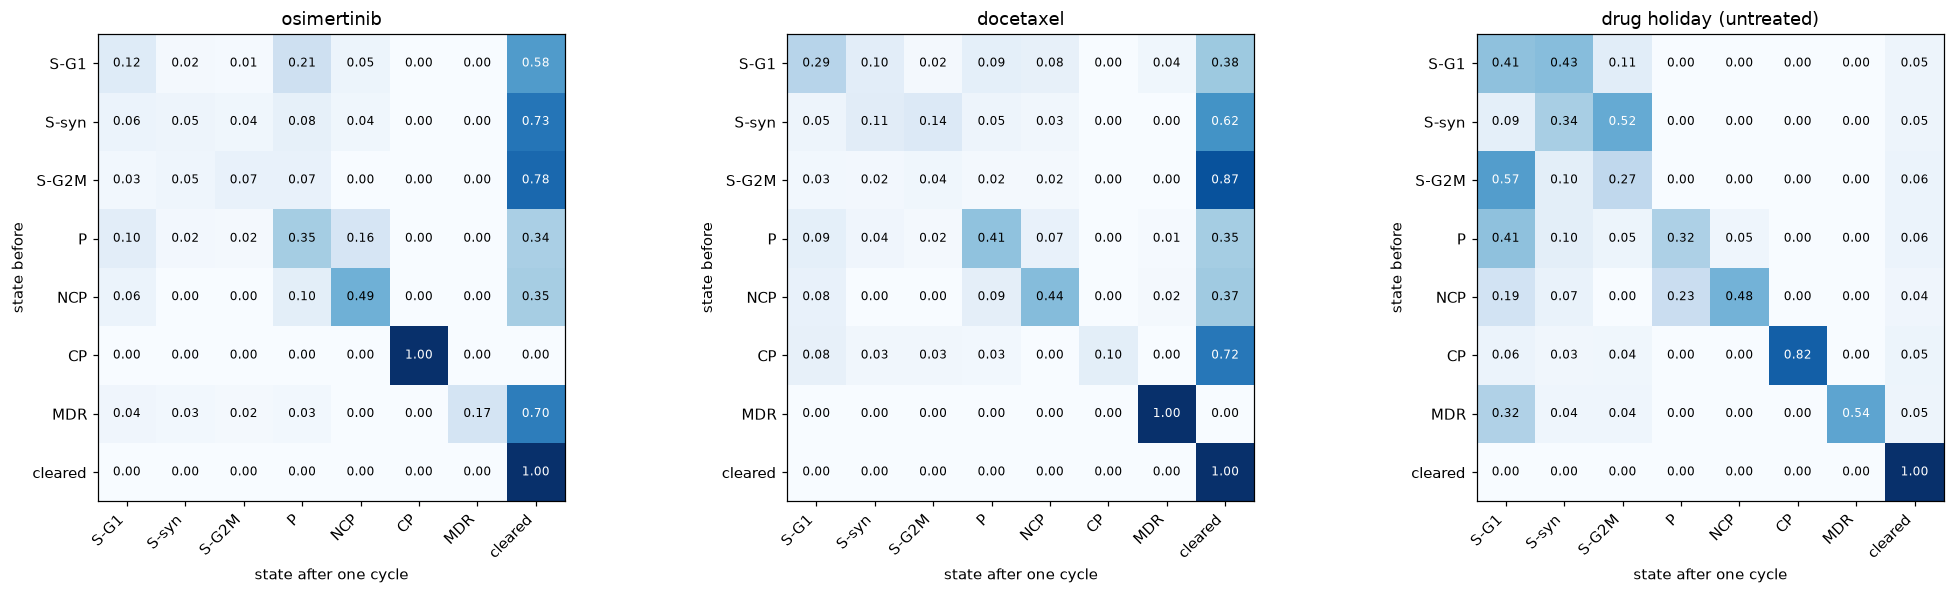

In [19]:
#Plot the transition matrices for docetaxel and the drug holiday.
fig, axes = plt.subplots(1, 3, figsize = (19, 5.5))
show_matrix(P_hat, "osimertinib", axes[0])
show_matrix(P_doc_df, "docetaxel", axes[1])
show_matrix(P_holiday_df, "drug holiday (untreated)", axes[2])
plt.tight_layout()
plt.show()

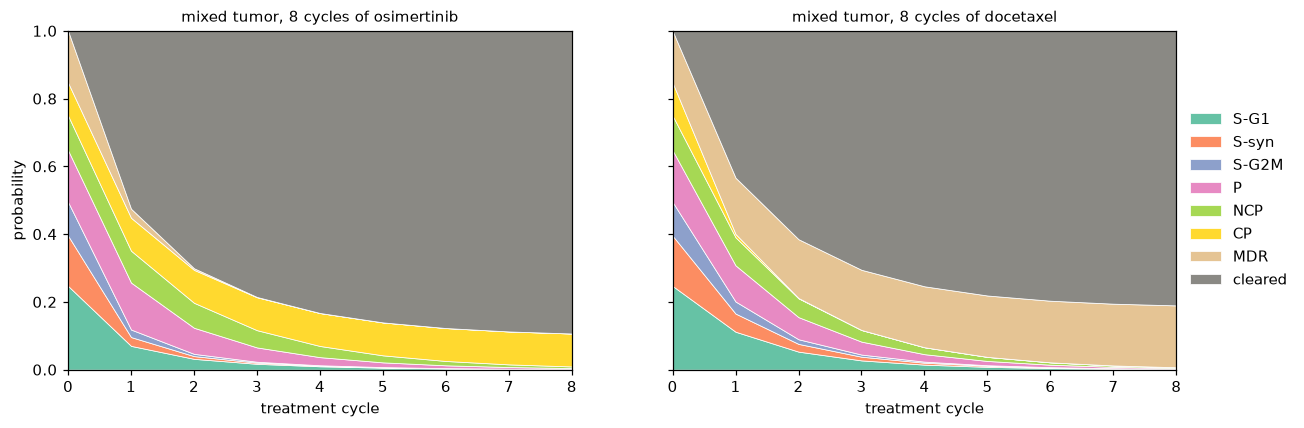

docetaxel, after 8 cycles:


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.002,0.001,0.0,0.002,0.002,0.0,0.183,0.81


docetaxel, after 50 cycles: {'S-G1': np.float64(0.0), 'S-syn': np.float64(0.0), 'S-G2M': np.float64(0.0), 'P': np.float64(0.0), 'NCP': np.float64(0.0), 'CP': np.float64(0.0), 'MDR': np.float64(0.183), 'cleared': np.float64(0.817)}


In [20]:
# Simulate the evolution of pi_mix under docetaxel 
traj_doc = evolve(pi_mix, P_doc, N_CYCLES)
fig, axes = plt.subplots(1, 2, figsize = (13, 4), sharey = True)
plot_trajectory(traj_mix, axes[0], "mixed tumor, 8 cycles of osimertinib")
plot_trajectory(traj_doc, axes[1], "mixed tumor, 8 cycles of docetaxel")
axes[0].set_ylabel("probability")
axes[1].legend(loc="center left", bbox_to_anchor = (1, 0.5), frameon = False)
plt.show()

print("docetaxel, after 8 cycles:")
display(pd.DataFrame(traj_doc[[-1]], columns = OUTCOMES).round(3))
print("docetaxel, after 50 cycles:", dict(zip(OUTCOMES, evolve(pi_mix, P_doc, 50)[-1].round(3)))) 

*Answer questions in markdown here.*
- Docetaxel clears every state except MDR, which is absorbing since it stays at 1. This is the opposite of osimertinib, where CP is absorbing and docetaxel kills CP easily. During the drug holiday, no state is absorbing. Very few cells die, and many resistant cells switch back to being drug-sensitive (an ex is MDR with turns into S-G1 at a 32% rate each cycle).
- Under docetaxel, everything is cleared except for the 18.3% of MDR. That is more than the MDR at the start because docetaxel creates MDR cells, so docetaxel alone can never clear this tumor. Neither drug works alone, but each kills the cells the other can't (osimertinib kills MDR, docetaxel kills CP).

## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

fraction of cells still alive after 8 cycles


,8x osimertinib,8x docetaxel,alternate O first (OD x4),alternate D first (DO x4)
all S-G1,0.0108,0.0727,0.0099,0.0109
all S-syn,0.0056,0.0124,0.0051,0.0047
all S-G2M,0.0036,0.0059,0.0032,0.0021
all P,0.0190,0.0545,0.0170,0.0154
all NCP,0.0216,0.0681,0.0190,0.0172
all CP,1.0000,0.0101,0.0064,0.0036
all MDR,0.0029,1.0000,0.0048,0.0073
measured mix,0.1066,0.1896,0.0094,0.0092


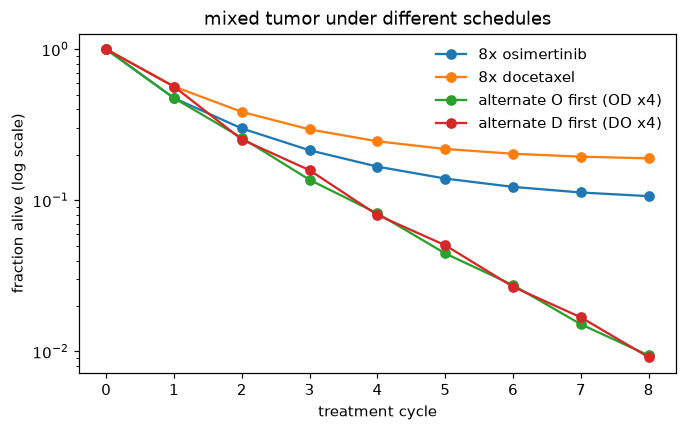

holiday rows for the resistant states:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
CP,0.059,0.033,0.036,0.0,0.0,0.82,0.000,0.052
MDR,0.319,0.044,0.044,0.0,0.0,0.00,0.542,0.051


fraction alive after 8 cycles, with and without holidays


,8x docetaxel,docetaxel + holiday (DH x4),8x osimertinib,osimertinib + holiday (OH x4),OD x4
all CP,0.0101,0.0194,1.0000,0.5682,0.0064
all MDR,1.0000,0.3107,0.0029,0.0144,0.0048
measured mix,0.1896,0.0928,0.1066,0.0840,0.0094


rounds needed to reach < 1% surviving cells (NaN = never, within 16 rounds)


,osimertinib,docetaxel,alternate O first,alternate D first
all S-G1,9.0,NaN,8,9
all S-syn,7.0,10.0,7,7
all S-G2M,6.0,6.0,6,6
all P,10.0,NaN,9,9
all NCP,10.0,NaN,10,10
all CP,NaN,9.0,8,7
all MDR,6.0,NaN,7,8
measured mix,NaN,NaN,8,8


In [21]:
## Add code here
from functools import reduce
DRUGS = {"O": P_osi, "D": P_doc, "H": P_holiday}

def schedule_matrix(plan):
    '''plan is a string such as "ODODODOD"; returns the product of the matrices in that order.'''
    return reduce(np.matmul, [DRUGS[c] for c in plan], np.eye(len(OUTCOMES)))

def alive_after(pi0, plan):
    return 1 - (pi0 @ schedule_matrix(plan))[-1]

STARTS = {**{f"all {s}": basis(s, P_hat) for s in STATES}, "measured mix": pi_mix}

PLANS = {"8x osimertinib": "O" * 8, "8x docetaxel": "D" * 8,
         "alternate O first (OD x4)": "OD" * 4, "alternate D first (DO x4)": "DO" * 4}
alive_table = pd.DataFrame({p: {k: alive_after(v, plan) for k, v in STARTS.items()}
                            for p, plan in PLANS.items()})
print("fraction of cells still alive after 8 cycles")
display(alive_table.round(4))

fig, ax = plt.subplots(figsize = (7, 4))
for p, plan in PLANS.items():
    ax.plot(range(9), [alive_after(pi_mix, plan[:t]) for t in range(9)], marker = "o", label = p)
ax.set_yscale("log"); ax.set_xlabel("treatment cycle"); ax.set_ylabel("fraction alive (log scale)")
ax.set_title("mixed tumor under different schedules"); ax.legend(frameon=False)
plt.show()

print("holiday rows for the resistant states:")
display(P_holiday_df.loc[["CP", "MDR"]].round(3))
HOLIDAY_PLANS = {"8x docetaxel": "D" * 8, "docetaxel + holiday (DH x4)": "DH" * 4,
                 "8x osimertinib": "O" * 8, "osimertinib + holiday (OH x4)": "OH" * 4,
                 "OD x4": "OD" * 4}
print("fraction alive after 8 cycles, with and without holidays")
display(pd.DataFrame({p: {k: alive_after(STARTS[k], plan) for k in ["all CP", "all MDR", "measured mix"]}
                      for p, plan in HOLIDAY_PLANS.items()}).round(4))

def rounds_needed(pi0, pattern, target = 0.01, max_rounds = 16):
    for n in range(1, max_rounds + 1):
        if alive_after(pi0, (pattern * max_rounds)[:n]) < target:
            return n
    return np.nan 

STRATS = {"osimertinib": "O", "docetaxel": "D", "alternate O first": "OD", "alternate D first": "DO"}
rx = pd.DataFrame({name: {k: rounds_needed(v, pat) for k, v in STARTS.items()}
                   for name, pat in STRATS.items()})
print("rounds needed to reach < 1% surviving cells (NaN = never, within 16 rounds)")
rx

*Answer questions here.*
- Alternating works much better. After 8 cycles, there is only about 1% of the mixed tumor is left with alternating, compared to the 11% with osimertinib alone and the 19% with docetaxel alone (the leftover of the two absorbing). This is because each drug kills the cells the other one can't.
- No. Either alternate leaves about 1% of the tumor.
- A drug holiday helps when the tumor is resistant to the only drug you're using. Without the drug, resistant cells turn back into sensitive cells, which the drug can then kill.
- If the tumor is mostly sensitive cells or MDR, use osimertinib for about 6–9 rounds. If it's mostly P or NCP, use osimertinib for about 10 rounds. If it has CP cells, alternate the two drugs starting with docetaxel, for about 7 rounds. For a mixed tumor, or if you're unsure what it's made of, alternate the drugs for 8 rounds. Avoid docetaxel alone, since it turns cells into MDR, which it can't kill.

## 4 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [22]:
rng = np.random.default_rng(100)

In [23]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [24]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

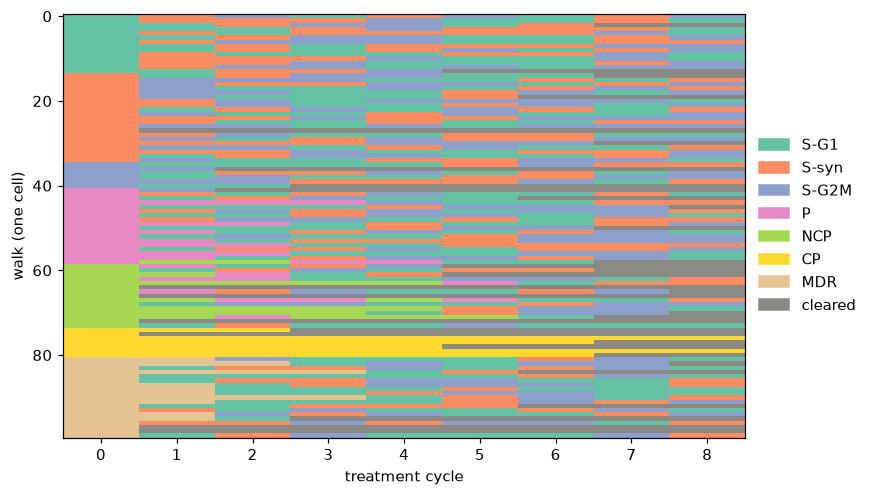

In [25]:
N_WALKS = 100
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [26]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

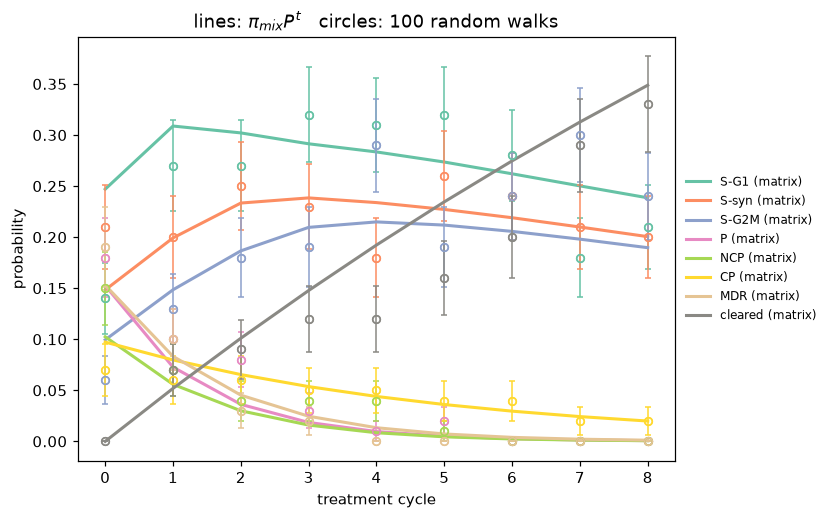

In [27]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

- With 10,000 walks, the circles almost exactly match the lines, and the gap is about 10 times smaller. More walks means more cells, which averages out the randomness.

In [28]:
for n_walks in [100, 10_000]:
    st = rng.choice(len(pi_mix), size=n_walks, p=pi_mix)
    W = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in st])
    fr = np.array([[np.mean(W[:, t] == j) for j in range(len(OUTCOMES))] for t in range(N_CYCLES + 1)])
    print(f"N_WALKS = {n_walks:>6}: max |simulated - exact| = {np.abs(fr - exact).max():.4f}, "
          f"mean = {np.abs(fr - exact).mean():.4f}")

N_WALKS =    100: max |simulated - exact| = 0.1215, mean = 0.0283
N_WALKS =  10000: max |simulated - exact| = 0.0099, mean = 0.0022


## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [29]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

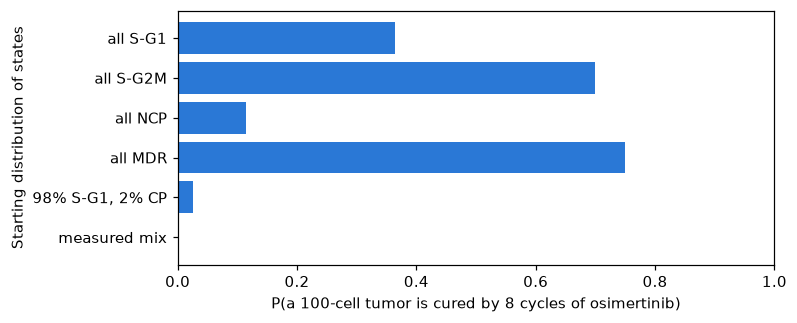

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.365,1.020,0.000
all S-G2M,0.700,0.340,0.000
all NCP,0.115,2.130,0.000
all MDR,0.750,0.275,0.000
"98% S-G1, 2% CP",0.025,3.200,0.636
measured mix,0.000,10.690,0.919


In [30]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_osi, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

- Docetaxel almost never cures a tumor, so it does much worse than osimertinib. This is because it turns cells into MDR, which it can't kill, so most of the surviving cells are MDR.

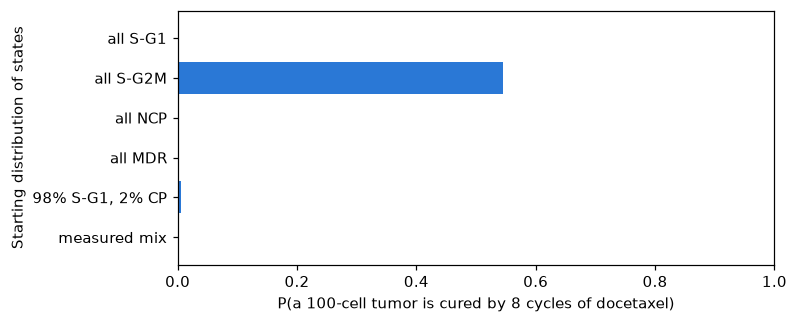

,P(cured),mean surviving cells,share of survivors that are MDR
start,,,
all S-G1,0.000,7.805,0.864
all S-G2M,0.545,0.610,0.631
all NCP,0.000,6.720,0.800
all MDR,0.000,100.000,1.000
"98% S-G1, 2% CP",0.005,6.960,0.866
measured mix,0.000,18.960,0.964


In [31]:
P_TUMOR, N_TUMOR_CYCLES = P_doc, 8   
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis = 1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are MDR":
                     (finals == OUTCOMES.index("MDR")).sum() / max(alive.sum(), 1)})
results_doc = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize = (7, 3))
ax.barh(results_doc.index[::-1], results_doc["P(cured)"][::-1], color = "#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of docetaxel)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results_doc.round(3)

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

osimertinib, 8 cycles: 11.51% +/- 0.10% (SEM) permanently resistant
95% CI [11.31%, 11.72%], one-sample t-test vs 10%: p = 5.5e-27


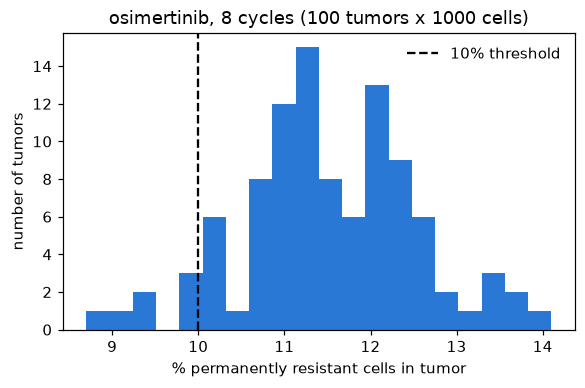

In [32]:
from scipy import stats

PERSISTER = [OUTCOMES.index("P"), OUTCOMES.index("NCP")]

def tumor_walks(pi0, plan, n_cells, rng):
    '''Run n_cells random walks at once (vectorized inverse-CDF sampling).
    plan is a list of transition matrices, one per cycle.
    Returns an (n_cells, n_cycles + 1) array of state indices.'''
    state = rng.choice(len(pi0), size = n_cells, p = pi0)
    path = [state]
    for M in plan:
        cdf = np.cumsum(M, axis = 1)
        u = rng.random(n_cells)
        state = np.minimum((u[:, None] > cdf[state]).sum(axis = 1), len(pi0) - 1)
        path.append(state)
    return np.array(path).T

def fraction_resistant(walks, k=3):
    '''Share of cells whose walk spends k or more CONSECUTIVE time points in P or NCP
    (moving between P and NCP still counts as staying a persister).'''
    in_pers = np.isin(walks, PERSISTER)
    run = np.zeros(len(walks), dtype = int)
    longest = np.zeros(len(walks), dtype = int)
    for t in range(walks.shape[1]):
        run = np.where(in_pers[:, t], run + 1, 0)
        longest = np.maximum(longest, run)
    return np.mean(longest >= k)

def simulate_resistance(pattern, n_cycles, n_tumors = 100, n_cells = 1000, pi0 = None):
    pi0 = pi_mix if pi0 is None else pi0
    plan = [DRUGS[c] for c in (pattern * n_cycles)[:n_cycles]]
    return np.array([fraction_resistant(tumor_walks(pi0, plan, n_cells, rng)) for _ in range(n_tumors)])

def summarize(fracs, threshold = 0.10):
    mean, sem = fracs.mean(), fracs.std(ddof = 1) / np.sqrt(len(fracs))
    lo, hi = stats.t.interval(0.95, len(fracs) - 1, loc = mean, scale = sem)
    t_stat, p_val = stats.ttest_1samp(fracs, threshold)
    return {"mean % PR": 100 * mean, "SEM %": 100 * sem,
            "95% CI low %": 100 * lo, "95% CI high %": 100 * hi,
            "p (H0: mean = 10%)": p_val, "% of tumors > 10% PR": 100 * np.mean(fracs > threshold)}

rng = np.random.default_rng(2026)

osi_fracs = simulate_resistance("O", 8)
s = summarize(osi_fracs)
print(f"osimertinib, 8 cycles: {s['mean % PR']:.2f}% +/- {s['SEM %']:.2f}% (SEM) permanently resistant")
print(f"95% CI [{s['95% CI low %']:.2f}%, {s['95% CI high %']:.2f}%], "
      f"one-sample t-test vs 10%: p = {s['p (H0: mean = 10%)']:.2g}")

plt.figure(figsize = (6, 3.5))
plt.hist(100 * osi_fracs, bins = 20, color = "#2a78d6")
plt.axvline(10, color = "k", ls = "--", label = "10% threshold")
plt.xlabel("% permanently resistant cells in tumor"); plt.ylabel("number of tumors")
plt.title("osimertinib, 8 cycles (100 tumors x 1000 cells)"); plt.legend(frameon = False)
plt.show()


<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

- For Osimertinib alone, about 85% of tumors have more than 10% permanently resistant cells after 4 cycles, rising to 96% at 8 cycles and 93% at 12.
- For docetaxel alone, only 13% of tumors are over 10% after 4 cycles, rising to 15% at 8 cycles and 23% at 12.
- When we alternate OD, 57% of tumors are over 10% after 4 cycles, 72% at 8 cycles, and 65% at 12.
- For Doxetaxel with drug holiday, 3% of tumors are over 10% after 4 cycles, 41% at 8 cycles, and 65% at 12.
- For more cycles, most of the treatment percetages go up as the cycles go up because the cells have more chances to stay in a persister state for 3 cycles in a row.

,,mean % PR,SEM %,95% CI low %,95% CI high %,p (H0: mean = 10%),% of tumors > 10% PR
schedule,cycles,,,,,,
osimertinib alone,4,11.103,0.100,10.905,11.301,0.000,85.0
docetaxel alone,4,8.668,0.113,8.445,8.891,0.000,13.0
alternating OD,4,10.147,0.093,9.963,10.331,0.117,57.0
docetaxel + drug holiday (DH),4,8.206,0.082,8.043,8.369,0.000,3.0
osimertinib alone,8,11.481,0.096,11.290,11.672,0.000,96.0
docetaxel alone,8,9.166,0.085,8.997,9.335,0.000,15.0
alternating OD,8,10.602,0.101,10.402,10.802,0.000,72.0
docetaxel + drug holiday (DH),8,9.766,0.092,9.583,9.949,0.013,41.0
osimertinib alone,12,11.623,0.089,11.447,11.799,0.000,93.0


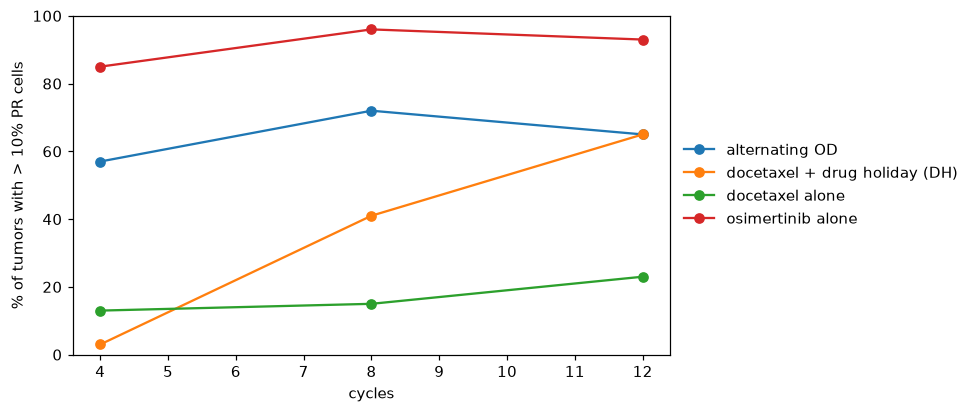

In [33]:
SCHEDULES = {"osimertinib alone": "O", "docetaxel alone": "D",
             "alternating OD": "OD", "docetaxel + drug holiday (DH)": "DH"}
rows = []
for n_cycles in [4, 8, 12]:
    for name, pattern in SCHEDULES.items():
        rows.append({"schedule": name, "cycles": n_cycles, **summarize(simulate_resistance(pattern, n_cycles))})
pr_table = pd.DataFrame(rows).set_index(["schedule", "cycles"])
display(pr_table.round(3))

ax = pr_table["% of tumors > 10% PR"].unstack("schedule").plot(marker = "o", figsize = (7, 4))
ax.set_ylabel("% of tumors with > 10% PR cells"); ax.set_ylim(0, 100)
ax.legend(frameon = False, loc = "center left", bbox_to_anchor = (1, 0.5))
plt.show()